# Step 7: Prioritization policy and business value

**Client:** NASA/JPL Planetary Defense Coordination Office (PDCO)
**Pillar assessed:** #4, *business value translation*, with explicit thresholds.

### What we build

A **priority queue** that tells, for each object in the catalogue, **when to observe it**:

| Tier | Decision |
|---|---|
| **Tier 1** | Observe **this cycle** |
| **Tier 2** | Observe **next cycle** |
| **Tier 3** | **Passive surveillance** by automated surveys |

### What we combine

| Building block | Source | Role in the decision |
|---|---|---|
| MOID | Catalogue (official measurement) | Can the orbit come close to Earth? |
| Estimated diameter and **upper bound** | Step 4 (regression) | Is the object large enough? Cautious version for "zero false negatives" |
| Pessimistic impact energy | Computed from step 4 | Severity, to order the queue |
| PHA probability | Step 5 (classification) | Safety net when the MOID is not reliable yet (newly discovered objects) |
| Cluster | Step 6 | Group observations into campaigns |
| Approaches 2026–2035, orbit uncertainty, discovery date | Catalogue and approach file | **Urgency** |

Here, MOID and H **may** be used: we are no longer evaluating a model, but making a decision with all the information available. Data leakage only concerned the training and evaluation in step 5.

Run notebooks 03 to 06 first.

## 1. Policy parameters

All thresholds are grouped here, with their justification. To test another policy, change them and rerun the notebook.

In [1]:
# --- Risk thresholds ---------------------------------------------------------
MOID_MAX_AU = 0.05             # official PHA definition (CNEOS)
MIN_DIAMETER_KM = 0.14         # 140 m: regional damage threshold (PHA definition, US Congress goal)
URGENT_APPROACH_LD = 20        # future approach closer than 20 lunar distances (≈ 0.05 AU) by 2035
UNCERTAIN_CONDITION_CODE = 7   # JPL orbit uncertainty from 0 (excellent) to 9 (very poor)
RECENT_DISCOVERY_DAYS = 365    # discovered within the year before the data extraction

# --- Physical assumptions for the energy ------------------------------------
DENSITY_KG_M3 = 2600           # average density of a rocky asteroid (assumption)
ESCAPE_VELOCITY_KMS = 11.2     # velocity added by Earth's gravity at impact
MT_TNT_J = 4.184e15            # 1 megaton of TNT in joules

# --- Cost assumptions (illustrative, to be replaced with the PDCO's real data)
OBS_PER_YEAR = {"Tier 1": 4, "Tier 2": 1, "Tier 3": 0}   # dedicated observations per object per year
HOURS_PER_OBSERVATION = 1.0
COST_PER_HOUR_USD = 5_000

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.max_columns", 30)

def find_project_dir() -> Path:
    for base in [Path.cwd(), *Path.cwd().parents]:
        for candidate in (base, base / "nasa-project"):
            if (candidate / "data" / "raw").is_dir():
                return candidate
    raise FileNotFoundError("Folder nasa-project/data/raw not found.")

PROJECT_DIR = find_project_dir()
RAW_DIR = PROJECT_DIR / "data" / "raw"
P = PROJECT_DIR / "data" / "processed"
INPUTS = {
    "diameters (step 4)": P / "04_diameter" / "catalogue_diameters.csv",
    "PHA scores (step 5)": P / "05_classification" / "catalogue_scores.csv",
    "clusters (step 6)": P / "06_clustering" / "catalogue_clusters.csv",
}
for name, f in INPUTS.items():
    if not f.exists():
        raise FileNotFoundError(f"Missing file: {name}. Run notebooks 03 to 06.")
PROCESSED_DIR = P / "07_risk_policy"
REPORT_DIR = PROJECT_DIR / "reports" / "07_risk_policy"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

TIER_COLORS = {"Tier 1": "#C0392B", "Tier 2": "#E07A2D", "Tier 3": "#8C8C8C"}
BLUE, GREY, RED = "#2878B5", "#8C8C8C", "#C0392B"
LABEL_BOX = dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.5)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})

def save(fig, name):
    fig.savefig(REPORT_DIR / f"{name}.png", dpi=160, bbox_inches="tight")

def fmt(n):
    return f"{n:,.0f}"

## 2. Assembling all the building blocks

In [3]:
asteroids = pd.read_csv(sorted(RAW_DIR.glob("near_earth_asteroids_2025*.csv"))[0], low_memory=False)
approaches = pd.read_csv(sorted(RAW_DIR.glob("asteroid_close_approaches_2015_2035*.csv"))[0], low_memory=False)
approaches["date"] = pd.to_datetime(approaches["close_approach_date"])
EXTRACTION = approaches.loc[approaches["is_future"], "date"].min().normalize()
print(f"Data extraction date: {EXTRACTION:%Y-%m-%d}")

# Closest future approach (after extraction), per object
future = approaches[approaches["is_future"]].sort_values("dist_lunar")
next_app = (future.groupby("designation").first()[["dist_lunar", "date"]]
            .rename(columns={"dist_lunar": "closest_approach_LD", "date": "closest_approach_date"}))
# Typical arrival velocity of the object (all its known approaches)
vinf = approaches.groupby("designation")["velocity_infinity_km_s"].median().rename("v_inf_kms")

df = (asteroids[["pdes", "full_name", "pha", "H", "moid_au", "condition_code", "first_obs", "class"]]
      .merge(pd.read_csv(INPUTS["diameters (step 4)"])[["pdes", "diameter_km", "diameter_km_low", "diameter_km_high", "diameter_source", "out_of_domain"]], on="pdes", how="left")
      .merge(pd.read_csv(INPUTS["PHA scores (step 5)"])[["pdes", "pha_proba", "flagged"]], on="pdes", how="left")
      .merge(pd.read_csv(INPUTS["clusters (step 6)"])[["pdes", "cluster"]], on="pdes", how="left")
      .merge(next_app, left_on="pdes", right_index=True, how="left")
      .merge(vinf, left_on="pdes", right_index=True, how="left"))
df["full_name"] = df["full_name"].str.strip()
df["first_obs"] = pd.to_datetime(df["first_obs"], errors="coerce")
print(f"{fmt(len(df))} objects, {fmt(df['closest_approach_LD'].notna().sum())} of them with an approach expected by 2035")

Data extraction date: 2026-03-25


41,281 objects, 3,289 of them with an approach expected by 2035


## 3. Severity: pessimistic impact energy

The kinetic energy of an impact is ½ m v². We estimate it for each object:

- **mass** = density × volume of a sphere of diameter D. We take the diameter's **upper bound** (step 4), for the cautious version;
- **impact velocity** = √(v∞² + 11.2²) km/s, where v∞ is the object's arrival velocity (median of its known approaches, or the catalogue median if it has none), and 11.2 km/s the acceleration due to Earth's gravity.

The energy is expressed in **megatons of TNT**. Benchmarks: Chelyabinsk (2013, ~20 m) ≈ 0.5 Mt; Tunguska (1908, ~50 m) ≈ 10 Mt; a 140 m object ≈ 100 Mt.

In [4]:
v_inf = df["v_inf_kms"].fillna(approaches["velocity_infinity_km_s"].median())
v_impact_ms = np.sqrt(v_inf ** 2 + ESCAPE_VELOCITY_KMS ** 2) * 1e3

def energy_mt(diameter_km):
    mass = DENSITY_KG_M3 * np.pi / 6 * (diameter_km * 1e3) ** 3
    return 0.5 * mass * v_impact_ms ** 2 / MT_TNT_J

df["impact_energy_Mt"] = energy_mt(df["diameter_km"])
df["impact_energy_Mt_high"] = energy_mt(df["diameter_km_high"])

ratio = (df["impact_energy_Mt_high"] / df["impact_energy_Mt"]).where(df["diameter_source"] == "predicted")
print(f"For a predicted diameter, the pessimistic energy is ×{ratio.median():.1f} the estimated energy "
      f"(the diameter is cubed).")
df[["diameter_km", "diameter_km_high", "impact_energy_Mt", "impact_energy_Mt_high"]].describe(percentiles=[0.5, 0.9, 0.99]).T

For a predicted diameter, the pessimistic energy is ×9.8 the estimated energy (the diameter is cubed).


,count,mean,std,min,50%,90%,99%,max
diameter_km,"41,281.000",0.199,0.430,0.000,0.062,0.519,1.665,37.675
diameter_km_high,"41,281.000",0.390,0.683,0.001,0.132,1.045,3.092,37.675
impact_energy_Mt,"41,281.000","71,100.654","9,350,739.236",0.000,9.794,"5,320.445","177,230.368","1,875,395,264.070"
impact_energy_Mt_high,"41,281.000","120,553.820","9,381,613.561",0.000,93.552,"42,651.421","1,078,665.997","1,875,395,264.070"


## 4. The decision rules

**Step A: risk.** Two categories, based on size:

- **Probable PHA**: MOID ≤ 0.05 AU **and** **estimated** diameter ≥ 140 m;
- **Possible PHA**: MOID ≤ 0.05 AU, estimated diameter < 140 m, but **upper bound** ≥ 140 m. The object could be dangerous if it is darker than expected.

**Step B: urgency.** An object is urgent if at least one condition holds:

- **close approach**: a pass closer than 20 lunar distances expected by 2035;
- **uncertain orbit**: `condition_code` ≥ 7, risk of "losing" the object for lack of observations;
- **recent discovery**: less than a year before the extraction; its MOID and size are still unreliable.

**Step C: the tier.**

| Tier | Rule |
|---|---|
| **Tier 1** | Probable PHA **and** urgent |
| **Tier 2** | Non-urgent probable PHA, **or** possible PHA, **or** recent discovery flagged by the step 5 model with an upper bound ≥ 140 m |
| **Tier 3** | Everything else |

The last tier 2 criterion is the step 5 model's **safety net**: for a newly discovered object, the MOID can still change a lot; if the model considers its profile dangerous, it is not left to passive surveys.

In [5]:
close_orbit = df["moid_au"] <= MOID_MAX_AU
probable = close_orbit & (df["diameter_km"] >= MIN_DIAMETER_KM)
possible = close_orbit & ~probable & (df["diameter_km_high"] >= MIN_DIAMETER_KM)

close_approach = df["closest_approach_LD"] < URGENT_APPROACH_LD
uncertain_orbit = df["condition_code"] >= UNCERTAIN_CONDITION_CODE
recent_discovery = df["first_obs"] >= EXTRACTION - pd.Timedelta(days=RECENT_DISCOVERY_DAYS)
urgent = close_approach | uncertain_orbit | recent_discovery
model_safety_net = recent_discovery & df["flagged"].fillna(False).astype(bool) & (df["diameter_km_high"] >= MIN_DIAMETER_KM)

tier1 = probable & urgent
tier2 = ~tier1 & (probable | possible | model_safety_net)
df["tier"] = np.select([tier1, tier2], ["Tier 1", "Tier 2"], default="Tier 3")
df["risk_category"] = np.select([probable, possible], ["Probable PHA", "Possible PHA"], default="—")

def reasons(i):
    r = []
    if probable[i]: r.append("probable PHA")
    if possible[i]: r.append("possible PHA (upper bound)")
    if close_approach[i]: r.append(f"approach at {df.at[i, 'closest_approach_LD']:.1f} LD")
    if uncertain_orbit[i]: r.append(f"uncertain orbit (code {int(df.at[i, 'condition_code'])})")
    if recent_discovery[i]: r.append("recent discovery")
    if model_safety_net[i] and not (probable[i] or possible[i]): r.append("flagged by the model (step 5)")
    return " · ".join(r)

df["reasons"] = [reasons(i) for i in df.index]

summary = df.groupby("tier").agg(
    objects=("pdes", "size"),
    official_PHAs=("pha", "sum"),
    median_high_energy_Mt=("impact_energy_Mt_high", "median"),
)
summary["catalogue_share_%"] = summary["objects"] / len(df) * 100
summary["share_of_official_PHAs_%"] = summary["official_PHAs"] / df["pha"].sum() * 100
summary.to_csv(REPORT_DIR / "tier_summary.csv")
summary

,objects,official_PHAs,median_high_energy_Mt,catalogue_share_%,share_of_official_PHAs_%
tier,,,,,
Tier 1,730,429,"3,358.529",1.768,16.896
Tier 2,4880,2098,"1,349.212",11.821,82.631
Tier 3,35671,12,42.769,86.410,0.473


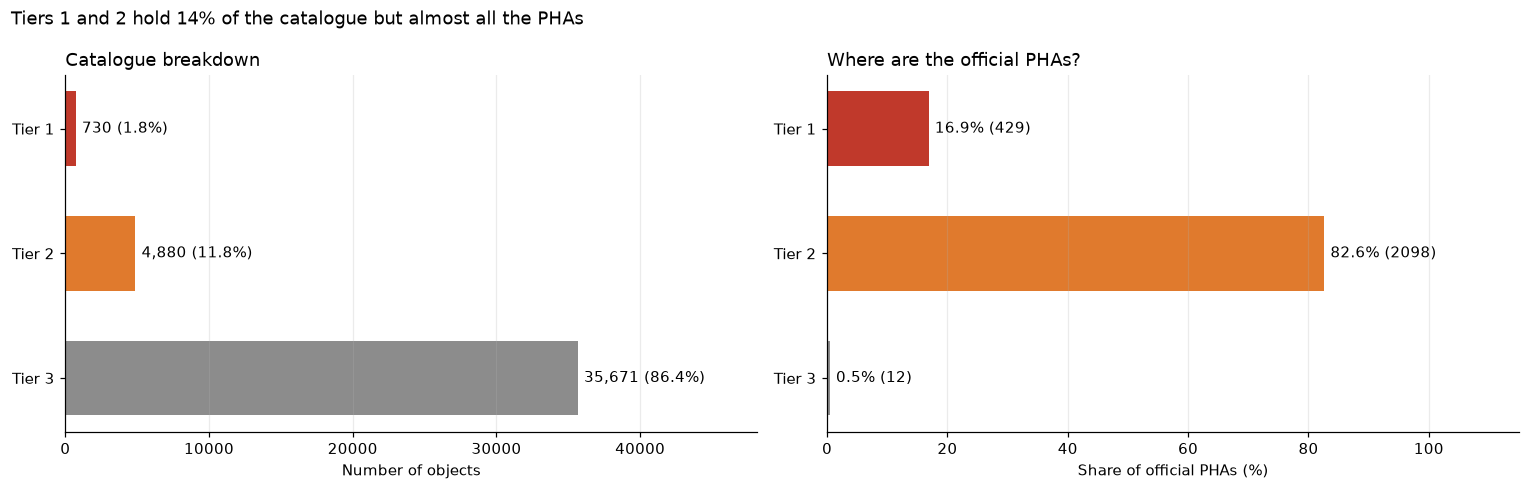

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
tiers = ["Tier 1", "Tier 2", "Tier 3"]
ax = axes[0]
bars = ax.barh(tiers[::-1], summary.loc[tiers[::-1], "objects"], color=[TIER_COLORS[t] for t in tiers[::-1]], height=0.6)
ax.bar_label(bars, labels=[f"{fmt(n)} ({p:.1f}%)" for n, p in zip(summary.loc[tiers[::-1], "objects"], summary.loc[tiers[::-1], "catalogue_share_%"])], padding=4)
ax.set_xlim(0, summary["objects"].max() * 1.35)
ax.set_xlabel("Number of objects")
ax.set_title("Catalogue breakdown", loc="left")
ax.grid(axis="y", visible=False)

ax = axes[1]
bars = ax.barh(tiers[::-1], summary.loc[tiers[::-1], "share_of_official_PHAs_%"], color=[TIER_COLORS[t] for t in tiers[::-1]], height=0.6)
ax.bar_label(bars, labels=[f"{p:.1f}% ({int(n)})" for p, n in zip(summary.loc[tiers[::-1], "share_of_official_PHAs_%"], summary.loc[tiers[::-1], "official_PHAs"])], padding=4)
ax.set_xlim(0, 115)
ax.set_xlabel("Share of official PHAs (%)")
ax.set_title("Where are the official PHAs?", loc="left")
ax.grid(axis="y", visible=False)
active = summary.loc[["Tier 1", "Tier 2"], "catalogue_share_%"].sum()
fig.suptitle(f"Tiers 1 and 2 hold {active:.0f}% of the catalogue but almost all the PHAs", x=0.01, ha="left")
fig.tight_layout()
save(fig, "tier_breakdown")
plt.show()

## 5. Check: does the policy honor "zero false negatives"?

We now use the official `pha` label **to check** the policy: how many official PHAs end up in tier 3?

In [7]:
missed = df[(df["tier"] == "Tier 3") & df["pha"]]
recall = 1 - len(missed) / df["pha"].sum()
print(f"Official PHAs in tier 1 or 2: {recall:.2%} ({fmt(df['pha'].sum() - len(missed))} out of {fmt(df['pha'].sum())})")
print(f"Official PHAs in tier 3: {len(missed)}")
print("Diameter source of these objects:", missed["diameter_source"].value_counts().to_dict())
missed[["pdes", "H", "moid_au", "diameter_source", "diameter_km", "diameter_km_high"]].sort_values("diameter_km")

Official PHAs in tier 1 or 2: 99.53% (2,527 out of 2,539)
Official PHAs in tier 3: 12
Diameter source of these objects: {'measured': 12}


,pdes,H,moid_au,diameter_source,diameter_km,diameter_km_high
13576,2015 TK238,21.900,0.014,measured,0.076,0.076
2688,518810,21.850,0.032,measured,0.083,0.083
625,154590,21.700,0.013,measured,0.086,0.086
7843,2010 FF10,21.800,0.037,measured,0.095,0.095
7981,2010 LK34,21.910,0.009,measured,0.108,0.108
11085,2014 BX2,21.890,0.004,measured,0.110,0.110
1063,264357,21.170,0.021,measured,0.113,0.113
14162,2016 CL136,21.300,0.028,measured,0.123,0.123
3711,877685,21.550,0.014,measured,0.124,0.124
7225,2009 FY4,21.000,0.043,measured,0.129,0.129


**Reading:** the few official PHAs left in tier 3 do have a MOID ≤ 0.05 AU, but their diameter has been **actually measured** and is **smaller than 140 m**. The official list classifies them as PHAs because their H is below 22, which assumes an albedo of 0.14; their measured size shows they are in fact brighter, hence smaller. The policy relies on the measurement rather than the approximation. This is a deliberate choice, to be flagged to the PDCO: if it prefers to follow the official list to the letter, it is enough to add the condition `pha == True` to tier 2.

**What the policy adds to the official list:**

In [8]:
hidden = df[probable & ~df["pha"]]
possible_only = df[possible & ~df["pha"]]
added = pd.DataFrame({
    "category": [
        "Probable PHAs missing from the official list",
        "Possible PHAs (upper bound ≥ 140 m) missing from the official list",
        "Recent discoveries flagged by the model, excluding probable or possible PHAs",
    ],
    "objects": [
        len(hidden),
        len(possible_only),
        int((model_safety_net & ~probable & ~possible).sum()),
    ],
})
added.to_csv(REPORT_DIR / "additions_vs_official_list.csv", index=False)
added

,category,objects
0,Probable PHAs missing from the official list,662
1,Possible PHAs (upper bound ≥ 140 m) missing fr...,2184
2,"Recent discoveries flagged by the model, exclu...",237


These objects have H > 22: they do not appear in the official list, which assumes an albedo of 0.14. But the step 4 model estimates them as darker, hence larger than 140 m ("probable"), or cannot rule out that they are ("possible"). For a "zero false negative" policy, they deserve follow-up.

## 6. Visualizing the policy

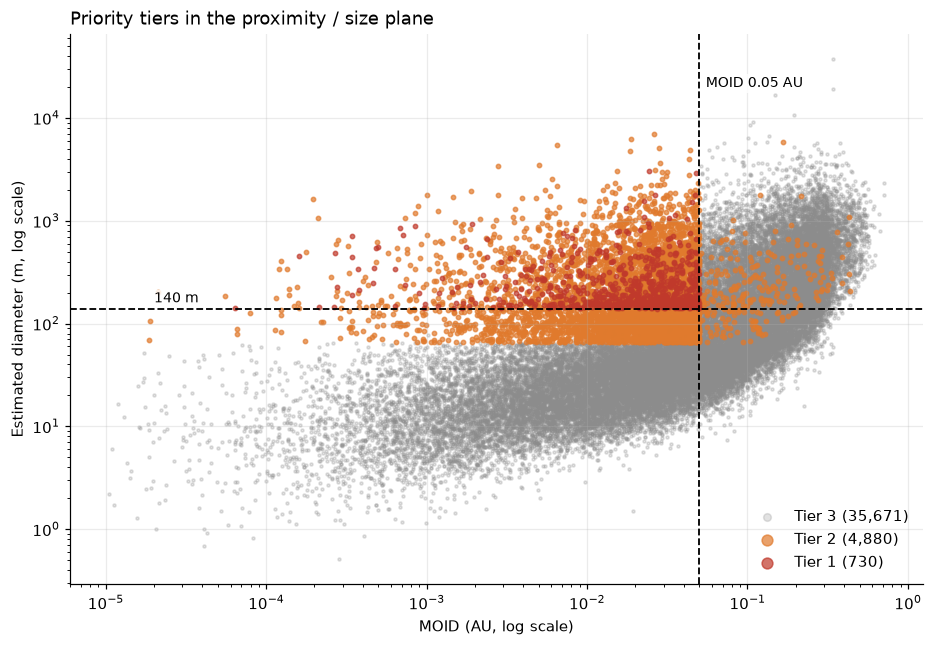

In [9]:
fig, ax = plt.subplots(figsize=(10, 6.5))
for tier in ["Tier 3", "Tier 2", "Tier 1"]:
    d = df[df["tier"] == tier]
    ax.scatter(d["moid_au"] + 1e-5, d["diameter_km"] * 1000, s=4 if tier == "Tier 3" else 8,
               alpha=0.25 if tier == "Tier 3" else 0.7, color=TIER_COLORS[tier],
               label=f"{tier} ({fmt(len(d))})", rasterized=True)
ax.set_xscale("log"); ax.set_yscale("log")
ax.axvline(MOID_MAX_AU, color="black", ls="--", lw=1.2)
ax.axhline(MIN_DIAMETER_KM * 1000, color="black", ls="--", lw=1.2)
ax.text(MOID_MAX_AU * 1.1, 2e4, f"MOID {MOID_MAX_AU} AU", fontsize=9, bbox=LABEL_BOX)
ax.text(2e-5, MIN_DIAMETER_KM * 1000 * 1.15, "140 m", fontsize=9, bbox=LABEL_BOX)
ax.set_xlabel("MOID (AU, log scale)")
ax.set_ylabel("Estimated diameter (m, log scale)")
ax.set_title("Priority tiers in the proximity / size plane", loc="left")
ax.legend(frameon=False, markerscale=2.5, loc="lower right")
save(fig, "tiers_moid_diameter")
plt.show()

**Reading:** tier 1 occupies the "close and large" corner. Tier 2 spills **below** the 140 m line: these are the possible PHAs, whose estimated diameter is below 140 m but whose upper bound exceeds it. This is the safety margin provided by the step 4 interval. The few orange points **to the right** of the MOID line are the recent discoveries caught by the step 5 model: their current MOID exceeds 0.05 AU, but it is still unreliable.

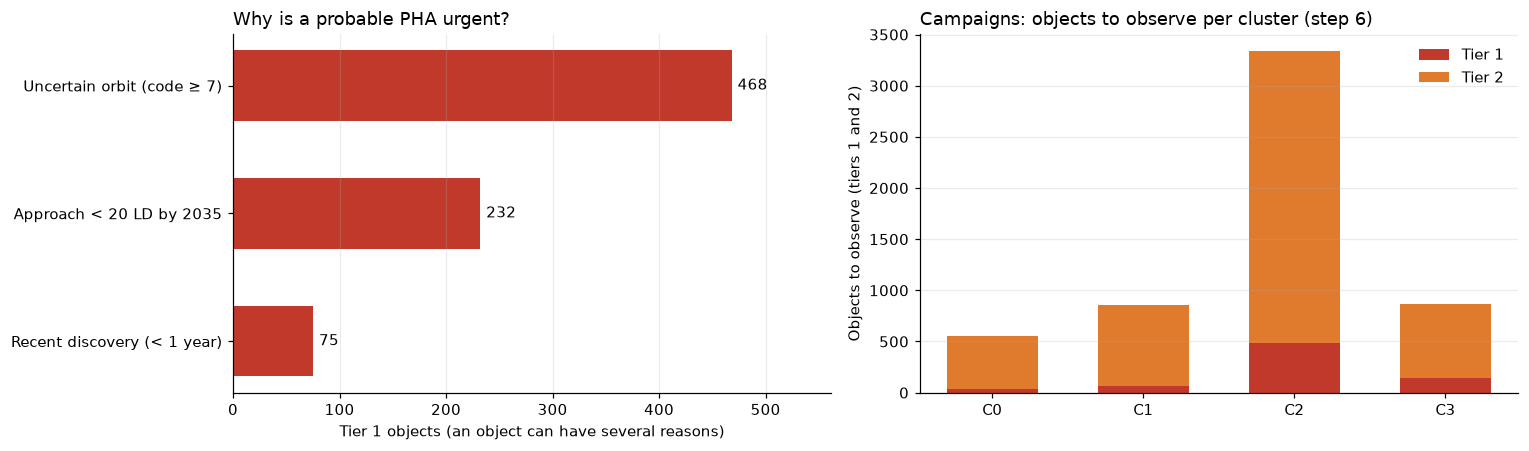

tier,Tier 1,Tier 2,Tier 3
cluster,,,
0.000,39,512,10451
1.000,62,793,9990
2.000,490,2847,9951
3.000,139,728,5148


In [10]:
t1 = df[df["tier"] == "Tier 1"]
reason_counts = pd.Series({
    "Approach < 20 LD by 2035": close_approach[t1.index].sum(),
    "Uncertain orbit (code ≥ 7)": uncertain_orbit[t1.index].sum(),
    "Recent discovery (< 1 year)": recent_discovery[t1.index].sum(),
}).sort_values()
cross = pd.crosstab(df["cluster"], df["tier"])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
ax = axes[0]
bars = ax.barh(reason_counts.index, reason_counts.values, color=TIER_COLORS["Tier 1"], height=0.55)
ax.bar_label(bars, labels=[fmt(v) for v in reason_counts.values], padding=4)
ax.set_xlim(0, reason_counts.max() * 1.2)
ax.set_xlabel("Tier 1 objects (an object can have several reasons)")
ax.set_title("Why is a probable PHA urgent?", loc="left")
ax.grid(axis="y", visible=False)

ax = axes[1]
bottom = np.zeros(len(cross))
for tier in ["Tier 1", "Tier 2"]:
    vals = cross.get(tier, pd.Series(0, index=cross.index)).to_numpy()
    ax.bar([f"C{int(c)}" for c in cross.index], vals, bottom=bottom, color=TIER_COLORS[tier], label=tier, width=0.6)
    bottom += vals
ax.set_ylabel("Objects to observe (tiers 1 and 2)")
ax.set_title("Campaigns: objects to observe per cluster (step 6)", loc="left")
ax.legend(frameon=False)
ax.grid(axis="x", visible=False)
fig.tight_layout()
save(fig, "reasons_and_clusters")
plt.show()
cross

## 7. Business value: telescope time

We compare the dedicated observing time needed each year under four policies, with the **same assumptions** (section 1): a closely followed object is observed 4 times a year, a normally followed object once a year, one hour per observation.

| Policy | Who is observed, and how often |
|---|---|
| Monitor everything | The whole catalogue, once a year |
| Rule "the orbit crosses Earth's orbit" | 73% of the catalogue (step 5), once a year |
| Official PHA list | The 2,539 PHAs, twice a year, without distinguishing urgency |
| **Our policy** | Tier 1: 4 times a year; tier 2: once a year; tier 3: passive surveys |

**Costs are illustrative assumptions**, to be replaced with the PDCO's real observing costs. What matters is the comparison between policies, which does not depend on the hourly cost.

In [11]:
rule = ((asteroids["q"] <= 1.05) & (asteroids["ad"] >= 0.95))
h = HOURS_PER_OBSERVATION
policies = pd.DataFrame([
    {"policy": "Monitor everything", "objects followed": len(df), "hours / year": len(df) * 1 * h,
     "official PHAs covered": df["pha"].sum(), "objects beyond the official list": int((~df["pha"]).sum())},
    {"policy": "Rule \"crosses Earth's orbit\"", "objects followed": int(rule.sum()), "hours / year": rule.sum() * 1 * h,
     "official PHAs covered": int(df.loc[rule.to_numpy(), "pha"].sum()), "objects beyond the official list": int((rule.to_numpy() & ~df["pha"]).sum())},
    {"policy": "Official PHA list", "objects followed": int(df["pha"].sum()), "hours / year": df["pha"].sum() * 2 * h,
     "official PHAs covered": int(df["pha"].sum()), "objects beyond the official list": 0},
    {"policy": "Our policy", "objects followed": int((df["tier"] != "Tier 3").sum()),
     "hours / year": sum(OBS_PER_YEAR[t] * (df["tier"] == t).sum() for t in OBS_PER_YEAR) * h,
     "official PHAs covered": int(df.loc[df["tier"] != "Tier 3", "pha"].sum()),
     "objects beyond the official list": int(((df["tier"] != "Tier 3") & ~df["pha"]).sum())},
]).set_index("policy")
policies["annual cost (M$, assumption)"] = policies["hours / year"] * COST_PER_HOUR_USD / 1e6
policies["% of official PHAs"] = policies["official PHAs covered"] / df["pha"].sum() * 100
policies.to_csv(REPORT_DIR / "policy_comparison.csv")
policies.round(1)

,objects followed,hours / year,official PHAs covered,objects beyond the official list,"annual cost (M$, assumption)",% of official PHAs
policy,,,,,,
Monitor everything,41281,"41,281.000",2539,38742,206.400,100.000
"Rule ""crosses Earth's orbit""",30348,"30,348.000",2523,27825,151.700,99.400
Official PHA list,2539,"5,078.000",2539,0,25.400,100.000
Our policy,5610,"7,800.000",2527,3083,39.000,99.500


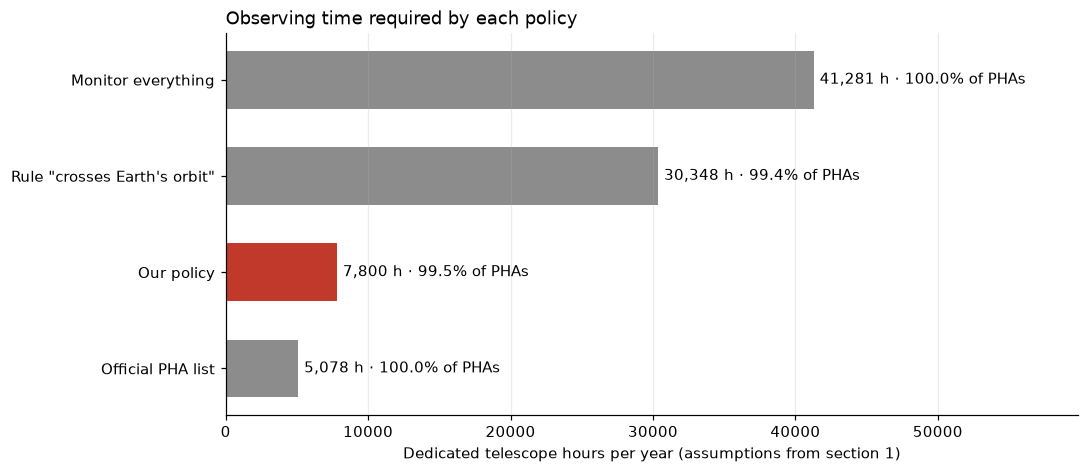

Compared with 'Monitor everything': 81% fewer hours
Compared with 'Rule "crosses Earth's orbit"': 74% fewer hours
Compared with 'Official PHA list': 54% more hours


In [12]:
fig, ax = plt.subplots(figsize=(10, 4.5))
order = policies["hours / year"].sort_values()
colors = [RED if n == "Our policy" else GREY for n in order.index]
bars = ax.barh(order.index, order.values, color=colors, height=0.6)
ax.bar_label(bars, labels=[f"{fmt(v)} h · {policies.loc[n, '% of official PHAs']:.1f}% of PHAs"
                           for n, v in zip(order.index, order.values)], padding=4)
ax.set_xlim(0, order.max() * 1.45)
ax.set_xlabel("Dedicated telescope hours per year (assumptions from section 1)")
ax.set_title("Observing time required by each policy", loc="left")
ax.grid(axis="y", visible=False)
save(fig, "policy_comparison")
plt.show()

ours = policies.loc["Our policy"]
for other in ["Monitor everything", "Rule \"crosses Earth's orbit\"", "Official PHA list"]:
    delta = 1 - ours["hours / year"] / policies.loc[other, "hours / year"]
    print(f"Compared with '{other}': {delta:.0%} fewer hours" if delta > 0 else
          f"Compared with '{other}': {-delta:.0%} more hours")

**Reading:**

- **Against "monitor everything" or the expert rule**, the policy divides the required telescope time by 4 to 5, while still covering almost all PHAs.
- **Against the official PHA list**, it requires about **50% more time**. This is not a saving but a **better use** of time:
  - it adds several thousand objects that **could** exceed 140 m but that the official list ignores, since it assumes a fixed albedo of 0.14;
  - it **concentrates** the effort: a small number of urgent objects (tier 1) get 4 observations a year, instead of treating all 2,539 PHAs the same way.

This is the argument to present to the PDCO: the value is not doing less, but **letting nothing slip through** and observing **first** what is pressing.

## 8. The priority queue

In [13]:
tier_rank = {"Tier 1": 0, "Tier 2": 1, "Tier 3": 2}
queue = (df.assign(_tier=df["tier"].map(tier_rank),
                   _date=df["closest_approach_date"].fillna(pd.Timestamp("2100-01-01")))
         .sort_values(["_tier", "_date", "impact_energy_Mt_high"], ascending=[True, True, False])
         .drop(columns=["_tier", "_date"]))
queue.insert(0, "rank", range(1, len(queue) + 1))

columns = ["rank", "tier", "pdes", "full_name", "risk_category", "reasons",
           "diameter_km", "diameter_km_high", "diameter_source", "moid_au",
           "closest_approach_LD", "closest_approach_date", "impact_energy_Mt_high", "pha_proba", "cluster", "pha"]
queue[columns].to_csv(PROCESSED_DIR / "priority_queue.csv", index=False)
queue[columns].head(40).to_csv(REPORT_DIR / "priority_queue_top40.csv", index=False)

show = queue[columns].head(15).copy()
show["diameter_m"] = (show.pop("diameter_km") * 1000).round(0)
show["diameter_high_m"] = (show.pop("diameter_km_high") * 1000).round(0)
show["closest_approach_date"] = show["closest_approach_date"].dt.strftime("%Y-%m-%d")
show[["rank", "tier", "full_name", "reasons", "diameter_m", "diameter_high_m", "moid_au",
      "closest_approach_LD", "closest_approach_date", "impact_energy_Mt_high", "pha_proba"]]

,rank,tier,full_name,reasons,diameter_m,diameter_high_m,moid_au,closest_approach_LD,closest_approach_date,impact_energy_Mt_high,pha_proba
4544,1,Tier 1,(2002 TB70),probable PHA · approach at 13.4 LD,189.000,405.000,0.017,13.390,2026-04-07,"2,273.430",0.856
40733,2,Tier 1,(2026 BK2),probable PHA · approach at 10.0 LD,216.000,461.000,0.003,10.000,2026-04-22,"3,048.181",0.783
2877,3,Tier 1,530520 (2011 LT17),probable PHA · approach at 16.0 LD,176.000,375.000,0.004,16.010,2026-06-12,"2,979.321",0.664
40086,4,Tier 1,(2025 WC4),probable PHA · approach at 10.2 LD · recent di...,397.000,848.000,0.014,10.150,2026-06-21,"48,889.540",0.708
561,5,Tier 1,152637 (1997 NC1),probable PHA · approach at 6.7 LD,775.000,"1,656.000",0.015,6.670,2026-06-27,"150,681.254",0.823
2780,6,Tier 1,523808 (2007 ML24),probable PHA · approach at 9.0 LD,436.000,931.000,0.025,9.040,2026-07-04,"53,354.382",0.846
815,7,Tier 1,173561 (2000 YV137),probable PHA · approach at 13.1 LD,757.000,"1,618.000",0.018,13.060,2026-08-09,"266,860.327",0.773
20729,8,Tier 1,(2019 NY2),probable PHA · approach at 6.5 LD,217.000,463.000,0.018,6.530,2026-08-10,"3,509.014",0.779
14077,9,Tier 1,(2016 BV14),probable PHA · approach at 19.0 LD,255.000,544.000,0.007,19.020,2026-08-10,"15,578.644",0.820
10613,10,Tier 1,(2013 QC11),probable PHA · approach at 14.4 LD,175.000,373.000,0.031,14.420,2026-08-13,"4,107.140",0.871


Tier 1 is sorted by **date of the closest approach expected by 2035** (most imminent first), then by **pessimistic energy**. This file (`data/processed/07_risk_policy/priority_queue.csv`) will be the data source of the Streamlit app at milestone 3.

## Summary

| Threshold | Value | Justification |
|---|---|---|
| MOID | ≤ 0.05 AU | Official PHA definition |
| Size | ≥ 140 m (estimated diameter = probable; upper bound = possible) | Regional damage threshold; upper bound for "zero false negatives" |
| Urgent approach | < 20 lunar distances by 2035 | ≈ 0.05 AU, same order of magnitude as the MOID threshold |
| Uncertain orbit | `condition_code` ≥ 7 | Risk of losing track of the object |
| Recent discovery | < 1 year | MOID and size still unreliable; blind spot of the step 5 model |
| Model safety net | probability ≥ step 5 threshold for 99% recall | Catches recent discoveries with a dangerous profile |

| Result | Value |
|---|---|
| Objects to observe actively (tiers 1 and 2) | about 14% of the catalogue (tier 1: less than 2%) |
| Official PHAs covered | 99.5%; the other 12 have a measured diameter below 140 m |
| Objects added compared with the official list | several thousand probable or possible PHAs darker than assumed |
| Telescope time | 4 to 5 times less than "monitor everything" or the expert rule; about 50% more than the official list, but allocated by urgency and extended to dark objects |